# Does mentoring reduce first-year attrition?

**The business question.** Since January 2023, Kestrel's new hires can opt into a mentoring program in their first month. Leaders see that mentored hires leave less often and want to make it mandatory. Before they do: **how much of that gap is the program, and how much is who chose to sign up?**

This is the LaLonde project again, on HR data you built yourself with SQL. One difference makes it a great practice ground: the data is simulated, so **the true effect is known**. It's in `data/_answer_key.json`. Don't open it until Part 6.

**Plan**
1. Build the analysis table (your capstone query)
2. Naive comparison
3. Who signs up? Balance
4. Adjust: regression, propensity weighting, doubly robust
5. A trap: the "bad control"
6. Check against the truth
7. What you'd tell leaders

In [1]:
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

from sqlkit import connect, run, EX

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
connect()

# use the reference capstone query so this notebook always runs;
# swap in your own 6.1 query to use the table you built
capstoneQuery = EX["6.1"]["solution"]
df = run(capstoneQuery)
print(f"{len(df):,} hires, {df.mentored.sum():,} mentored ({df.mentored.mean():.0%})")
df.head()

2,382 hires, 838 mentored (35%)


,employee_id,mentored,hire_source,location,gender,prior_experience_years,department_at_hire,level_at_hire,comp_ratio_at_hire,left_within_12m,first_pulse_engagement
0,102901,0,Job Board,New York,Woman,5,Talent,1,1.011,1,2.500
1,102902,0,Recruiter,Austin,Man,2,Content,1,0.949,0,3.000
2,102903,0,Job Board,Austin,Man,6,Marketing,1,0.863,0,3.250
3,102904,0,Job Board,Remote,Man,5,Product,2,1.191,0,3.000
4,102905,1,Recruiter,Los Angeles,Man,12,Marketing,4,1.100,0,2.000


## 1. The naive comparison

The outcome is binary: `left_within_12m` = 1 if they left within a year of hire. So a difference in means is a difference in **rates**, in percentage points (pp).

In [2]:
rates = df.groupby("mentored")["left_within_12m"].agg(["mean", "count"])
rates.index = ["not mentored", "mentored"]
naive = rates.loc["mentored", "mean"] - rates.loc["not mentored", "mean"]
p1, n1 = rates.loc["mentored", ["mean", "count"]]
p0, n0 = rates.loc["not mentored", ["mean", "count"]]
naiveSe = np.sqrt(p1 * (1 - p1) / n1 + p0 * (1 - p0) / n0)
print(rates)
print(f"\nnaive difference: {naive * 100:+.1f} pp  (95% ci {100 * (naive - 1.96 * naiveSe):+.1f} to "
      f"{100 * (naive + 1.96 * naiveSe):+.1f})")

              mean  count
not mentored 0.325   1544
mentored     0.177    838

naive difference: -14.9 pp  (95% ci -18.3 to -11.4)


Mentored hires leave far less often, and the interval is tight. A leader would read this as "mentoring cuts first-year attrition roughly in half." Notebook 2 of the LaLonde project should make you suspicious.

## 2. Who signs up?

In [3]:
model = pd.get_dummies(df, columns=["hire_source", "location", "department_at_hire"], dtype=float)
model["level_3_plus"] = (model.level_at_hire >= 3).astype(float)
balanceCols = ["hire_source_Referral", "hire_source_University", "location_Remote", "level_3_plus",
               "level_at_hire", "comp_ratio_at_hire", "prior_experience_years",
               "department_at_hire_Engineering", "department_at_hire_Product"]

def smd(x, t, w=None):
    x, t = np.asarray(x, float), np.asarray(t)
    w = np.ones_like(x) if w is None else np.asarray(w, float)
    m1, m0 = np.average(x[t == 1], weights=w[t == 1]), np.average(x[t == 0], weights=w[t == 0])
    return (m1 - m0) / np.sqrt((x[t == 1].var(ddof=1) + x[t == 0].var(ddof=1)) / 2)

balance = pd.DataFrame({
    "mentored_mean": model.loc[model.mentored == 1, balanceCols].mean(),
    "not_mentored_mean": model.loc[model.mentored == 0, balanceCols].mean(),
    "smd": [smd(model[c], model.mentored) for c in balanceCols],
})
balance

,mentored_mean,not_mentored_mean,smd
hire_source_Referral,0.405,0.178,0.514
hire_source_University,0.062,0.140,-0.260
location_Remote,0.172,0.365,-0.447
level_3_plus,0.447,0.240,0.448
level_at_hire,2.415,1.905,0.440
comp_ratio_at_hire,1.017,0.989,0.352
prior_experience_years,6.069,4.468,0.415
department_at_hire_Engineering,0.338,0.295,0.091
department_at_hire_Product,0.158,0.131,0.074


Mentored hires are more often **referrals**, less often **remote**, more senior, and paid higher in their band. Ask yourself: do those same things predict staying, regardless of mentoring? If yes, they're **confounders**, and the naive gap mixes them with the program's effect.

## 3. Adjust

### 3a. Regression (linear probability model)

$$\text{left}_i = \alpha + \tau\,\text{mentored}_i + \beta' X_i + \varepsilon_i$$

With a binary outcome, $\tau$ is a difference in probabilities. Robust standard errors handle the non-constant variance a 0/1 outcome creates.

In [4]:
xFormula = ("C(hire_source) + C(location) + C(department_at_hire) + C(level_at_hire) "
            "+ comp_ratio_at_hire + prior_experience_years + C(gender)")
lpm = smf.ols(f"left_within_12m ~ mentored + {xFormula}", data=df).fit(cov_type="HC2")
print(f"regression-adjusted: {lpm.params['mentored'] * 100:+.1f} pp  (se {lpm.bse['mentored'] * 100:.1f})")

regression-adjusted: -7.8 pp  (se 2.0)


### 3b. Propensity scores, overlap, and IPW for the ATT

Same steps as LaLonde notebook 3: model who enrolls, check overlap, weight comparison hires by $e/(1-e)$.

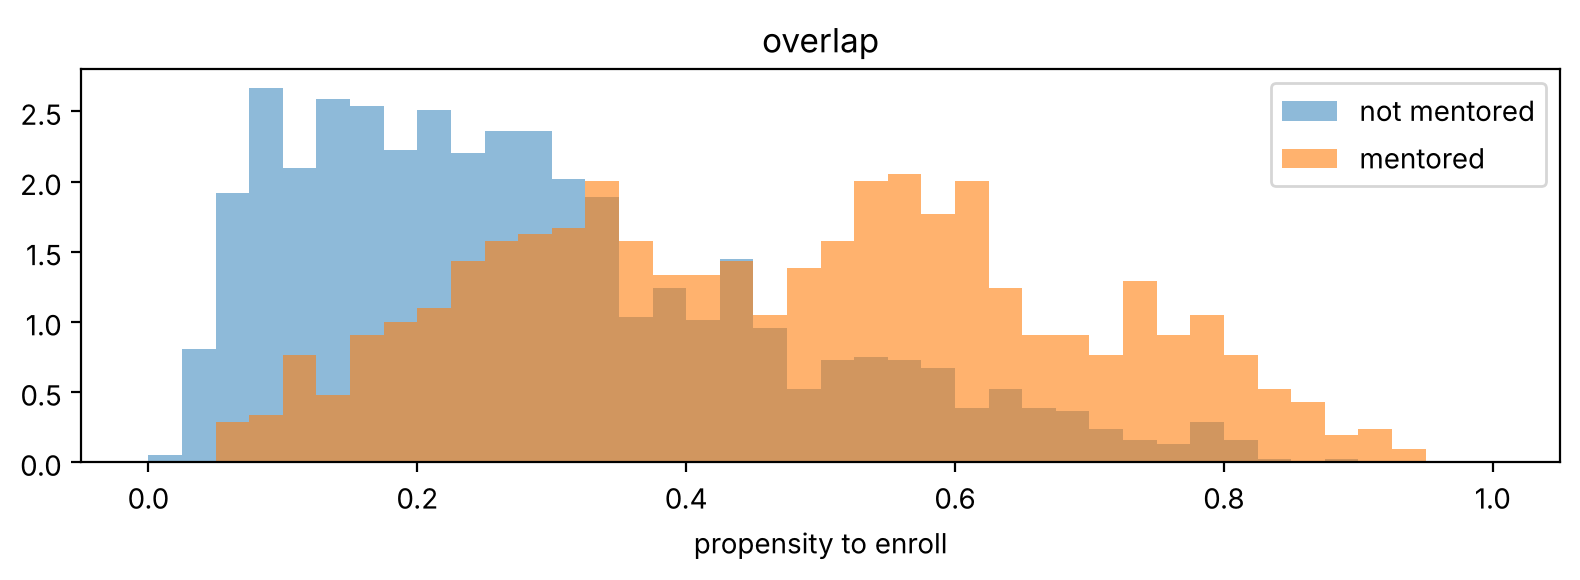

In [5]:
psModel = smf.logit(f"mentored ~ {xFormula}", data=df).fit(disp=0)
df["ps"] = psModel.predict(df)

fig, ax = plt.subplots(figsize=(8, 3))
bins = np.linspace(0, 1, 41)
ax.hist(df.loc[df.mentored == 0, "ps"], bins=bins, alpha=0.5, density=True, label="not mentored")
ax.hist(df.loc[df.mentored == 1, "ps"], bins=bins, alpha=0.6, density=True, label="mentored")
ax.set_xlabel("propensity to enroll")
ax.set_title("overlap")
ax.legend()
plt.tight_layout()
plt.show()

Much better overlap than LaLonde: enrollment was a choice many kinds of hires made, so nearly every mentored hire has comparable non-mentored hires. In a real HR program, that's common, and it makes adjustment far more trustworthy.

In [6]:
def ipwAtt(d, outcome="left_within_12m"):
    w = np.where(d.mentored == 1, 1.0, d.ps / (1 - d.ps))
    isT = d.mentored == 1
    return d.loc[isT, outcome].mean() - np.average(d.loc[~isT, outcome], weights=w[~isT]), w

attIpw, weights = ipwAtt(df)
df["w"] = weights
print(f"IPW ATT: {attIpw * 100:+.1f} pp")

after = pd.DataFrame({"before": balance["smd"],
                      "after IPW": [smd(model[c], model.mentored, df.w) for c in balanceCols]})
after

IPW ATT: -6.5 pp


,before,after IPW
hire_source_Referral,0.514,-0.003
hire_source_University,-0.260,0.002
location_Remote,-0.447,0.005
level_3_plus,0.448,0.011
level_at_hire,0.440,-0.002
comp_ratio_at_hire,0.352,-0.018
prior_experience_years,0.415,0.004
department_at_hire_Engineering,0.091,-0.019
department_at_hire_Product,0.074,0.018


### 3c. Doubly robust (AIPW)

Fit an outcome model on non-mentored hires, then correct its errors with the weights (see LaLonde notebook 4).

In [7]:
def drAtt(d, outcome="left_within_12m", formula=xFormula):
    isT = d.mentored == 1
    m0 = smf.ols(f"{outcome} ~ {formula}", data=d[~isT]).fit()
    resid = d[outcome] - m0.predict(d)
    w = np.where(isT, 1.0, d.ps / (1 - d.ps))
    return resid[isT].mean() - np.average(resid[~isT], weights=w[~isT])

attDr = drAtt(df)
print(f"doubly robust ATT: {attDr * 100:+.1f} pp")

# bootstrap the whole pipeline for a confidence interval
rng = np.random.default_rng(7)
boot = []
for b in range(300):
    s = df.sample(len(df), replace=True, random_state=rng.integers(1e9)).reset_index(drop=True)
    s["ps"] = smf.logit(f"mentored ~ {xFormula}", data=s).fit(disp=0).predict(s)
    boot.append((ipwAtt(s)[0], drAtt(s)))
boot = pd.DataFrame(boot, columns=["ipw", "dr"]) * 100
print(boot.quantile([0.025, 0.975]).round(1).rename(index={0.025: "ci_low", 0.975: "ci_high"}))

doubly robust ATT: -6.5 pp


            ipw      dr
ci_low  -10.300 -10.200
ci_high  -2.600  -2.400


## 4. A trap: the "bad control"

A colleague suggests: *"Engagement predicts attrition. Add each hire's first engagement-survey score to the model."* Sounds rigorous. Try it.

In [8]:
hasPulse = df.dropna(subset=["first_pulse_engagement"]).copy()
withoutIt = smf.ols(f"left_within_12m ~ mentored + {xFormula}", data=hasPulse).fit()
withIt = smf.ols(f"left_within_12m ~ mentored + {xFormula} + first_pulse_engagement", data=hasPulse).fit()
print(f"same hires, without engagement: {withoutIt.params['mentored'] * 100:+.1f} pp")
print(f"same hires, WITH engagement:    {withIt.params['mentored'] * 100:+.1f} pp")
print(f"hires dropped because they never answered a pulse: {len(df) - len(hasPulse):,}")

same hires, without engagement: -7.8 pp
same hires, WITH engagement:    -2.9 pp
hires dropped because they never answered a pulse: 169


Adding engagement shrinks the estimate. That's not more rigor. It's a mistake, for two reasons:

1. **It's a mediator.** The first pulse comes *after* mentoring starts, and part of how mentoring works is by raising engagement. Controlling for it removes part of the effect you're trying to measure.
2. **It selects on survival.** Only people still employed get surveyed. People who left in their first weeks drop out of the analysis. You're now studying "hires who lasted long enough to answer a survey."

**Rule:** only adjust for things measured *before* treatment. In interviews this is called a **bad control** or **post-treatment bias**.

## 5. Check against the truth

naive difference                        -14.900
regression                               -7.800
IPW (ATT)                                -6.500
doubly robust (ATT)                      -6.500
regression + engagement (bad control)    -2.900
TRUE ATT (simulation)                    -6.400


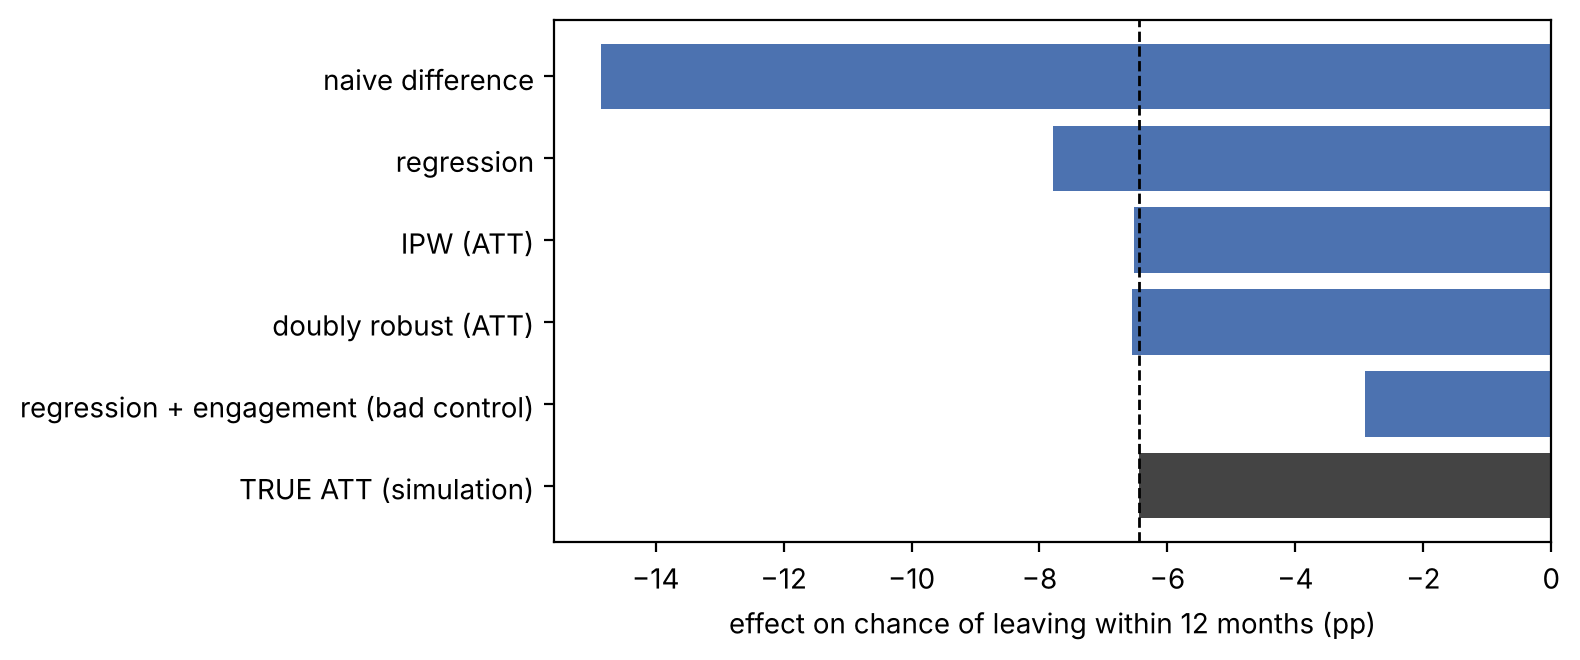

In [9]:
with open("data/_answer_key.json") as f:
    truth = json.load(f)

scoreboard = pd.Series({
    "naive difference": naive,
    "regression": lpm.params["mentored"],
    "IPW (ATT)": attIpw,
    "doubly robust (ATT)": attDr,
    "regression + engagement (bad control)": withIt.params["mentored"],
    "TRUE ATT (simulation)": truth["true_ATT"],
}) * 100
print(scoreboard.round(1).to_string())

fig, ax = plt.subplots(figsize=(8, 3.4))
order = scoreboard.index[::-1]
ax.barh(order, scoreboard[order], color=["#444" if "TRUE" in k else "#4c72b0" for k in order])
ax.axvline(scoreboard["TRUE ATT (simulation)"], color="black", ls="--", lw=1)
ax.axvline(0, color="grey", lw=0.6)
ax.set_xlabel("effect on chance of leaving within 12 months (pp)")
plt.tight_layout()
plt.show()

The naive gap is more than double the true effect. Adjusting for the real confounders brings the estimate close to the truth, within the bootstrap interval. **Mentoring works, but by much less than the raw numbers suggest.** If leaders had planned the rollout around the naive number, they'd have expected more than twice the real benefit.

One more subtlety: the true ATT (effect on people who *chose* mentoring) and the true ATE (effect if *everyone* got it) are different numbers in `_answer_key.json`. Making the program mandatory is an ATE question, so be careful about which number you hand to leaders.

## 6. What you'd tell leaders

> **Mentoring lowers first-year attrition, but by less than half as much as the raw comparison suggests.** Hires who chose mentoring were already more likely to stay: more referrals, fewer remote hires, more senior, better paid within their band. After accounting for those differences, mentoring reduces the chance of leaving in the first year by about 6 to 7 percentage points (plausible range roughly 3 to 10). The data supports keeping the program. Before making it mandatory, run a staggered rollout by site to confirm the effect holds for hires who wouldn't have opted in.

---

## Your turn
1. **Swap in your own capstone query** (top of the notebook) and rerun. Same numbers?
2. **Omitted confounder:** drop `comp_ratio_at_hire` from `xFormula`. How far does the estimate move? That tells you how much rides on having pay data.
3. **Heterogeneity:** estimate the effect separately for remote and non-remote hires. Is the program worth more for one group? (Watch your sample sizes.)
4. **Negative-control outcome:** mentoring shouldn't change whether someone is *let go* (involuntary termination for performance or conduct). Add a `left_involuntary_12m` column to your capstone query and estimate the "effect" with the same pipeline. It should be near zero. What would it mean if it weren't?
5. **Explain it out loud** in two minutes, as if to a VP of HR. Then again as if to a statistician.